# Short-Term Wind Generation Forecasting for Great Britain Using Weather and Time-Aware Machine Learning

## Project overview

This project investigates short-term wind generation forecasting for Great Britain using historical electricity generation, weather variables, and time-aware machine learning.

This is a continuous regression forecasting task. The aim is to predict wind generation using information that would be available at or before the forecast time, such as calendar variables, lagged generation, rolling historical statistics, and weather variables.

## Research question

How accurately can hourly wind generation be forecast using weather variables, lagged generation features, and time-aware machine learning models?

## Secondary question

Which model provides the best balance between forecasting accuracy, robustness, and interpretability?


##  Reproducibility setup


This section imports the required Python libraries and fixes the random seed used throughout the notebook. Setting a fixed seed helps make model training, validation splits, and sampling-based analyses more reproducible.

In [1]:
# Core libraries
import os
import sys
import random
import warnings
from pathlib import Path
import numpy as np
import pandas as pd
# Plotting
import matplotlib
import matplotlib.pyplot as plt

# Scikit-learn utilities
import sklearn
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import TimeSeriesSplit, GridSearchCV
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.inspection import permutation_importance

# Models
from sklearn.linear_model import Ridge, ElasticNet
from sklearn.svm import LinearSVR
from sklearn.neural_network import MLPRegressor
from sklearn.ensemble import (
    ExtraTreesRegressor,
    RandomForestRegressor,
    GradientBoostingRegressor,
    HistGradientBoostingRegressor,
    AdaBoostRegressor
)

# Statistical testing and interpretability
from scipy.stats import wilcoxon

# Reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
warnings.filterwarnings("ignore")

# Plot defaults
plt.rcParams["figure.figsize"] = (10, 4)
plt.rcParams["axes.grid"] = False


##  Data loading and initial inspection

The project uses three data sources:

1. `time_series_60min_singleindex.csv`  
   This contains hourly electricity generation and load variables, including the wind generation target.

2. `weather_data.csv`  
   This contains historical country-level weather variables such as temperature and radiation.

3. `london_nwp_data.csv`  
   This is created from the Open-Meteo archive API and saved locally. It contains additional weather variables such as wind speed, wind direction, temperature, surface pressure, humidity, and radiation.

In [2]:
# Define local dataset paths and key timestamp/target columns.
TIME_SERIES_PATH = "time_series_60min_singleindex.csv"
WEATHER_PATH = "weather_data.csv"
NWP_PATH = "london_nwp_data.csv"

TIMESTAMP_COL = "utc_timestamp"
TARGET_COL = "GB_UKM_wind_generation_actual"


In [3]:
# Read column headers
ts_columns = pd.read_csv(TIME_SERIES_PATH, nrows=0).columns.tolist()
weather_columns = pd.read_csv(WEATHER_PATH, nrows=0).columns.tolist()
nwp_columns = pd.read_csv(NWP_PATH, nrows=0).columns.tolist()

print("Number of columns in time-series file:", len(ts_columns))
print("Number of columns in uploaded weather file:", len(weather_columns))
print("Number of columns in saved API/NWP file:", len(nwp_columns))

Number of columns in time-series file: 300
Number of columns in uploaded weather file: 85
Number of columns in saved API/NWP file: 9


In [4]:
initial_ts_cols = [
    TIMESTAMP_COL,
    TARGET_COL,
    "GB_UKM_wind_onshore_generation_actual",
    "GB_UKM_wind_offshore_generation_actual",
    "GB_UKM_wind_capacity",
    "GB_UKM_wind_onshore_capacity",
    "GB_UKM_wind_offshore_capacity",
    "GB_UKM_load_actual_entsoe_transparency",
    "GB_UKM_load_forecast_entsoe_transparency",
    "GB_UKM_solar_generation_actual",
]

initial_ts_cols = [col for col in initial_ts_cols if col in ts_columns]

ts_df = pd.read_csv(
    TIME_SERIES_PATH,
    usecols=initial_ts_cols,
    parse_dates=[TIMESTAMP_COL]
)

ts_df[TIMESTAMP_COL] = pd.to_datetime(
    ts_df[TIMESTAMP_COL],
    utc=True
).dt.tz_convert(None)

ts_df = ts_df.sort_values(TIMESTAMP_COL).reset_index(drop=True)

print("Time-series data shape:", ts_df.shape)
display(ts_df.head())


Time-series data shape: (50401, 10)


,utc_timestamp,GB_UKM_load_actual_entsoe_transparency,GB_UKM_load_forecast_entsoe_transparency,GB_UKM_solar_generation_actual,GB_UKM_wind_capacity,GB_UKM_wind_generation_actual,GB_UKM_wind_offshore_capacity,GB_UKM_wind_offshore_generation_actual,GB_UKM_wind_onshore_capacity,GB_UKM_wind_onshore_generation_actual
0,2014-12-31 23:00:00,NaN,NaN,NaN,12212.0,NaN,4040.0,NaN,8173.0,NaN
1,2015-01-01 00:00:00,27607.0,NaN,NaN,12214.0,NaN,4040.0,NaN,8174.0,385.0
2,2015-01-01 01:00:00,27948.0,NaN,NaN,12214.0,1148.0,4040.0,117.0,8174.0,1041.0
3,2015-01-01 02:00:00,25210.0,NaN,NaN,12214.0,1139.0,4040.0,120.0,8174.0,1020.0
4,2015-01-01 03:00:00,23693.0,NaN,NaN,12214.0,1053.0,4040.0,115.0,8174.0,938.0


In [5]:
#Duplicates

print("\nDuplicate timestamps:", ts_df[TIMESTAMP_COL].duplicated().sum())



Duplicate timestamps: 0


In [6]:
#Missing Values 

print("\nMissing values:")
display(ts_df.isna().sum().sort_values(ascending=False))




Missing values:


GB_UKM_wind_capacity                        6600
GB_UKM_wind_offshore_capacity               6600
GB_UKM_wind_onshore_capacity                6600
GB_UKM_load_forecast_entsoe_transparency     888
GB_UKM_load_actual_entsoe_transparency       176
GB_UKM_wind_generation_actual                129
GB_UKM_wind_onshore_generation_actual        128
GB_UKM_solar_generation_actual                55
GB_UKM_wind_offshore_generation_actual        41
utc_timestamp                                  0
dtype: int64

In [7]:
#Target Summary 

print("\nTarget summary:")
display(ts_df[TARGET_COL].describe())


Target summary:


count    50272.000000
mean      4749.794737
std       2912.022711
min          8.000000
25%       2351.000000
50%       4248.000000
75%       6727.000000
max      14477.000000
Name: GB_UKM_wind_generation_actual, dtype: float64

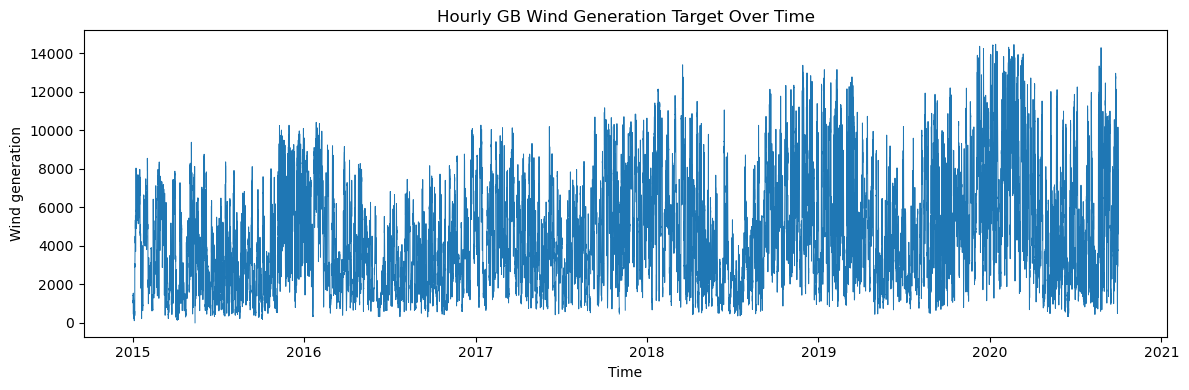

In [8]:
# Hourly wind generation series

plt.figure(figsize=(12, 4))
plt.plot(ts_df[TIMESTAMP_COL], ts_df[TARGET_COL], linewidth=0.7)
plt.title("Hourly GB Wind Generation Target Over Time")
plt.xlabel("Time")
plt.ylabel("Wind generation")
plt.tight_layout()
plt.show()

In [9]:
# Select weather columns

weather_cols = [
    TIMESTAMP_COL,
    "GB_temperature",
    "GB_radiation_direct_horizontal",
    "GB_radiation_diffuse_horizontal"
]

weather_cols = [col for col in weather_cols if col in weather_columns]

# Load weather data

weather_df = pd.read_csv(
    WEATHER_PATH,
    usecols=weather_cols,
    parse_dates=[TIMESTAMP_COL]
)

# Clean timestamps

weather_df[TIMESTAMP_COL] = pd.to_datetime(
    weather_df[TIMESTAMP_COL],
    utc=True
).dt.tz_convert(None)

weather_df = weather_df.sort_values(TIMESTAMP_COL).reset_index(drop=True)

print("weather data shape:", weather_df.shape)
display(weather_df.head())



weather data shape: (350640, 4)


,utc_timestamp,GB_temperature,GB_radiation_direct_horizontal,GB_radiation_diffuse_horizontal
0,1980-01-01 00:00:00,-1.249,0.0,0.0
1,1980-01-01 01:00:00,-1.377,0.0,0.0
2,1980-01-01 02:00:00,-1.449,0.0,0.0
3,1980-01-01 03:00:00,-1.481,0.0,0.0
4,1980-01-01 04:00:00,-1.433,0.0,0.0


In [10]:
#Missing Values

print("\nWeather missing values:")
display(weather_df.isna().sum())


Weather missing values:


utc_timestamp                      0
GB_temperature                     0
GB_radiation_direct_horizontal     0
GB_radiation_diffuse_horizontal    0
dtype: int64

In [11]:
nwp_df = pd.read_csv(
    NWP_PATH,
    parse_dates=[TIMESTAMP_COL]
)

nwp_df[TIMESTAMP_COL] = pd.to_datetime(
    nwp_df[TIMESTAMP_COL],
    utc=True
).dt.tz_convert(None)

nwp_df = nwp_df.sort_values(TIMESTAMP_COL).reset_index(drop=True)

print("Saved API/NWP data shape:", nwp_df.shape)
display(nwp_df.head())



Saved API/NWP data shape: (50424, 9)


,wind_speed_10m,wind_speed_100m,wind_direction_10m,wind_direction_100m,temperature_2m,surface_pressure,relative_humidity_2m,direct_radiation,utc_timestamp
0,9.7,23.2,243,254,-2.2,1033.7,95,0.0,2014-12-31 00:00:00
1,8.9,22.1,238,251,-2.3,1033.6,95,0.0,2014-12-31 01:00:00
2,9.2,22.2,231,245,-2.6,1033.3,95,0.0,2014-12-31 02:00:00
3,10.0,23.4,229,239,-2.6,1033.2,95,0.0,2014-12-31 03:00:00
4,11.0,25.6,232,238,-2.3,1032.7,96,0.0,2014-12-31 04:00:00


In [12]:
#Missing Values

print("\nNWP missing values:")
display(nwp_df.isna().sum().sort_values(ascending=False))




NWP missing values:


wind_speed_10m          0
wind_speed_100m         0
wind_direction_10m      0
wind_direction_100m     0
temperature_2m          0
surface_pressure        0
relative_humidity_2m    0
direct_radiation        0
utc_timestamp           0
dtype: int64

In [13]:
#NWP dataset summary

print("\nNWP summary:")
display(nwp_df.describe().T)


NWP summary:


,count,mean,min,25%,50%,75%,max,std
wind_speed_10m,50424.0,14.891224,0.0,9.1,13.7,19.4,53.7,7.599325
wind_speed_100m,50424.0,24.646736,0.0,16.9,23.7,31.3,81.7,11.344068
wind_direction_10m,50424.0,196.942587,1.0,126.0,220.0,258.0,360.0,91.995196
wind_direction_100m,50424.0,198.813759,0.0,129.0,222.0,262.0,360.0,92.564482
temperature_2m,50424.0,11.311457,-6.0,6.8,11.1,15.6,35.2,6.121356
surface_pressure,50424.0,1013.646089,968.9,1007.6,1014.7,1020.6,1047.5,10.562109
relative_humidity_2m,50424.0,78.391639,25.0,69.0,82.0,90.0,100.0,14.772383
direct_radiation,50424.0,71.45633,0.0,0.0,0.0,72.0,769.0,139.921631
utc_timestamp,50424,2017-11-15 11:29:59.999999744,2014-12-31 00:00:00,2016-06-08 05:45:00,2017-11-15 11:30:00,2019-04-24 17:15:00,2020-09-30 23:00:00,NaN


## Leakage audit and target definition

The target variable is:

`GB_UKM_wind_generation_actual`

This project must avoid both future leakage and same-time target leakage.

A key leakage risk is using same-time actual wind generation components to predict total wind generation. 
The model only uses information that would be available at forecast time like:

- calendar features generated from the timestamp;
- lagged target values;
- rolling statistics computed from past values only;
- weather variables available for the forecast timestamp;
- known-ahead capacity or forecast variables.


Target missing values: 129


count    50272.000000
mean      4749.794737
std       2912.022711
min          8.000000
25%       2351.000000
50%       4248.000000
75%       6727.000000
max      14477.000000
Name: GB_UKM_wind_generation_actual, dtype: float64

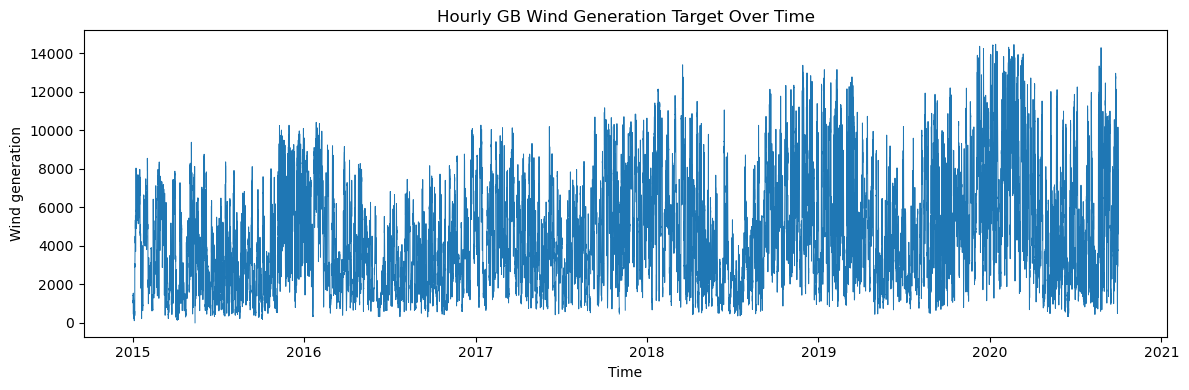

In [14]:
# Plot target over time.

print("Target missing values:", ts_df[TARGET_COL].isna().sum())

display(ts_df[TARGET_COL].describe())

plt.figure(figsize=(12, 4))
plt.plot(ts_df[TIMESTAMP_COL], ts_df[TARGET_COL], linewidth=0.7)
plt.title("Hourly GB Wind Generation Target Over Time")
plt.xlabel("Time")
plt.ylabel("Wind generation")
plt.tight_layout()
plt.show()

Correlation between target and same-time onshore+offshore actual generation:
1.0


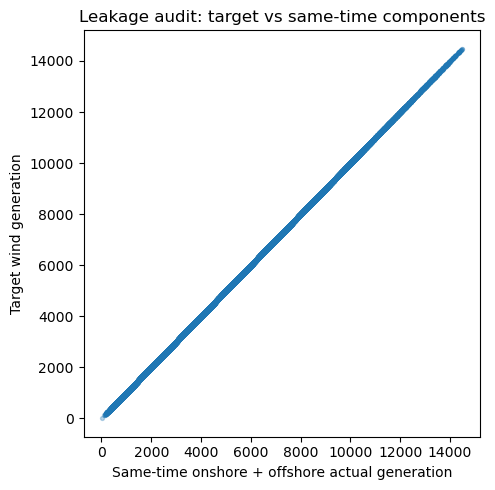

In [15]:
# Select same-time wind component columns

component_cols = [
    col for col in [
        "GB_UKM_wind_onshore_generation_actual",
        "GB_UKM_wind_offshore_generation_actual"
    ]
    if col in ts_df.columns
]


component_sum = ts_df[component_cols].sum(axis=1)

leakage_audit_df = pd.DataFrame({
    "target": ts_df[TARGET_COL],
    "onshore_plus_offshore": component_sum
}).dropna()

# Check correlation
corr = leakage_audit_df["target"].corr(
    leakage_audit_df["onshore_plus_offshore"]
)

print("Correlation between target and same-time onshore+offshore actual generation:")
print(round(corr, 5))

# Plot target against same-time components
plt.figure(figsize=(5, 5))
plt.scatter(
    leakage_audit_df["onshore_plus_offshore"],
    leakage_audit_df["target"],
    alpha=0.3,
    s=8
)
plt.xlabel("Same-time onshore + offshore actual generation")
plt.ylabel("Target wind generation")
plt.title("Leakage audit: target vs same-time components")
plt.tight_layout()
plt.show()


## Feature engineering

This section creates the modelling dataframe for wind generation forecasting.

The electricity target data is merged with the uploaded weather data and the saved Open-Meteo/API weather data using the timestamp column. Calendar features, lagged target features, rolling historical features, and wind-direction sine/cosine features are then created.

To avoid leakage, same-time actual wind generation component columns are not used directly. Lag and rolling features are created from past target values only. Rolling statistics are calculated after shifting the target, so the current target value is not included in its own predictors.


In [16]:
# Safe electricity columns for modelling base
safe_ts_cols = [
    TIMESTAMP_COL,
    TARGET_COL,
    "GB_UKM_wind_capacity",
    "GB_UKM_wind_onshore_capacity",
    "GB_UKM_wind_offshore_capacity",
    "GB_UKM_load_forecast_entsoe_transparency"
]

safe_ts_cols = [col for col in safe_ts_cols if col in ts_df.columns]

base_df = ts_df[safe_ts_cols].copy()
base_df = base_df.sort_values(TIMESTAMP_COL).reset_index(drop=True)

print("Base dataframe shape:", base_df.shape)
display(base_df.head())

Base dataframe shape: (50401, 6)


,utc_timestamp,GB_UKM_wind_generation_actual,GB_UKM_wind_capacity,GB_UKM_wind_onshore_capacity,GB_UKM_wind_offshore_capacity,GB_UKM_load_forecast_entsoe_transparency
0,2014-12-31 23:00:00,NaN,12212.0,8173.0,4040.0,NaN
1,2015-01-01 00:00:00,NaN,12214.0,8174.0,4040.0,NaN
2,2015-01-01 01:00:00,1148.0,12214.0,8174.0,4040.0,NaN
3,2015-01-01 02:00:00,1139.0,12214.0,8174.0,4040.0,NaN
4,2015-01-01 03:00:00,1053.0,12214.0,8174.0,4040.0,NaN


Same-time actual onshore and offshore wind generation are deliberately excluded from the modelling dataframe because they are direct components of total wind generation and would leak target information if used at the same timestamp.

In [17]:
# Merge uploaded weather data
feature_df = base_df.merge(
    weather_df,
    on=TIMESTAMP_COL,
    how="left",
    validate="one_to_one"
)

# Merge saved API/NWP weather data
feature_df = feature_df.merge(
    nwp_df,
    on=TIMESTAMP_COL,
    how="left",
    validate="one_to_one"
)

feature_df = feature_df.sort_values(TIMESTAMP_COL).reset_index(drop=True)

print("Merged feature dataframe shape:", feature_df.shape)
print("Date range:", feature_df[TIMESTAMP_COL].min(), "to", feature_df[TIMESTAMP_COL].max())

display(feature_df.head())

print("\nMissing values after merge:")
display(feature_df.isna().sum().sort_values(ascending=False).head(20))

Merged feature dataframe shape: (50401, 17)
Date range: 2014-12-31 23:00:00 to 2020-09-30 23:00:00


,utc_timestamp,GB_UKM_wind_generation_actual,GB_UKM_wind_capacity,GB_UKM_wind_onshore_capacity,GB_UKM_wind_offshore_capacity,GB_UKM_load_forecast_entsoe_transparency,GB_temperature,GB_radiation_direct_horizontal,GB_radiation_diffuse_horizontal,wind_speed_10m,wind_speed_100m,wind_direction_10m,wind_direction_100m,temperature_2m,surface_pressure,relative_humidity_2m,direct_radiation
0,2014-12-31 23:00:00,NaN,12212.0,8173.0,4040.0,NaN,6.425,0.0,0.0,20.3,35.7,205,208,4.7,1030.6,93,0.0
1,2015-01-01 00:00:00,NaN,12214.0,8174.0,4040.0,NaN,6.565,0.0,0.0,21.1,36.8,207,211,4.7,1030.2,93,0.0
2,2015-01-01 01:00:00,1148.0,12214.0,8174.0,4040.0,NaN,6.715,0.0,0.0,20.6,35.0,209,212,5.0,1029.7,93,0.0
3,2015-01-01 02:00:00,1139.0,12214.0,8174.0,4040.0,NaN,6.893,0.0,0.0,19.9,33.6,215,218,5.3,1029.6,93,0.0
4,2015-01-01 03:00:00,1053.0,12214.0,8174.0,4040.0,NaN,7.093,0.0,0.0,18.7,32.0,214,218,5.7,1029.7,93,0.0



Missing values after merge:


GB_UKM_wind_capacity                        6600
GB_UKM_wind_onshore_capacity                6600
GB_UKM_wind_offshore_capacity               6600
GB_radiation_diffuse_horizontal             6576
GB_temperature                              6576
GB_radiation_direct_horizontal              6576
GB_UKM_load_forecast_entsoe_transparency     888
GB_UKM_wind_generation_actual                129
wind_direction_100m                            0
relative_humidity_2m                           0
surface_pressure                               0
temperature_2m                                 0
utc_timestamp                                  0
wind_direction_10m                             0
wind_speed_100m                                0
wind_speed_10m                                 0
direct_radiation                               0
dtype: int64

In [18]:
feature_df["hour"] = feature_df[TIMESTAMP_COL].dt.hour
feature_df["dayofweek"] = feature_df[TIMESTAMP_COL].dt.dayofweek
feature_df["month"] = feature_df[TIMESTAMP_COL].dt.month

feature_df["hour_sin"] = np.sin(2 * np.pi * feature_df["hour"] / 24)
feature_df["hour_cos"] = np.cos(2 * np.pi * feature_df["hour"] / 24)

feature_df["dayofweek_sin"] = np.sin(2 * np.pi * feature_df["dayofweek"] / 7)
feature_df["dayofweek_cos"] = np.cos(2 * np.pi * feature_df["dayofweek"] / 7)

feature_df["month_sin"] = np.sin(2 * np.pi * feature_df["month"] / 12)
feature_df["month_cos"] = np.cos(2 * np.pi * feature_df["month"] / 12)

# Drop raw calendar integers
feature_df = feature_df.drop(columns=["hour", "dayofweek", "month"])

calendar_features = [
    "hour_sin", "hour_cos",
    "dayofweek_sin", "dayofweek_cos",
    "month_sin", "month_cos"
]

display(feature_df[[TIMESTAMP_COL] + calendar_features].head())

,utc_timestamp,hour_sin,hour_cos,dayofweek_sin,dayofweek_cos,month_sin,month_cos
0,2014-12-31 23:00:00,-0.258819,0.965926,0.974928,-0.222521,-2.449294e-16,1.000000
1,2015-01-01 00:00:00,0.000000,1.000000,0.433884,-0.900969,5.000000e-01,0.866025
2,2015-01-01 01:00:00,0.258819,0.965926,0.433884,-0.900969,5.000000e-01,0.866025
3,2015-01-01 02:00:00,0.500000,0.866025,0.433884,-0.900969,5.000000e-01,0.866025
4,2015-01-01 03:00:00,0.707107,0.707107,0.433884,-0.900969,5.000000e-01,0.866025


In [19]:
# Create past target lag features

lag_hours = [1, 2, 3, 6, 12, 24, 48, 168]

for lag in lag_hours:
    feature_df[f"target_lag_{lag}"] = feature_df[TARGET_COL].shift(lag)

# Store lag feature names

lag_features = [f"target_lag_{lag}" for lag in lag_hours]

display(feature_df[[TIMESTAMP_COL, TARGET_COL] + lag_features].head(175))

,utc_timestamp,GB_UKM_wind_generation_actual,target_lag_1,target_lag_2,target_lag_3,target_lag_6,target_lag_12,target_lag_24,target_lag_48,target_lag_168
0,2014-12-31 23:00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2015-01-01 00:00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2015-01-01 01:00:00,1148.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,2015-01-01 02:00:00,1139.0,1148.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,2015-01-01 03:00:00,1053.0,1139.0,1148.0,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...
170,2015-01-08 01:00:00,6376.0,6525.0,6821.0,7118.0,7722.0,7595.0,4394.0,4751.0,1148.0
171,2015-01-08 02:00:00,6075.0,6376.0,6525.0,6821.0,7615.0,7685.0,4341.0,5109.0,1139.0
172,2015-01-08 03:00:00,6127.0,6075.0,6376.0,6525.0,7231.0,7729.0,4471.0,5136.0,1053.0
173,2015-01-08 04:00:00,6023.0,6127.0,6075.0,6376.0,7118.0,8044.0,4588.0,5174.0,1048.0


In [20]:
past_target = feature_df[TARGET_COL].shift(1)

# Create rolling features from past values only

feature_df["target_rolling_mean_3"] = past_target.rolling(window=3).mean()
feature_df["target_rolling_mean_6"] = past_target.rolling(window=6).mean()
feature_df["target_rolling_mean_24"] = past_target.rolling(window=24).mean()
feature_df["target_rolling_std_24"] = past_target.rolling(window=24).std()
feature_df["target_rolling_mean_168"] = past_target.rolling(window=168).mean()

rolling_features = [
    "target_rolling_mean_3",
    "target_rolling_mean_6",
    "target_rolling_mean_24",
    "target_rolling_std_24",
    "target_rolling_mean_168"
]

display(feature_df[[TIMESTAMP_COL, TARGET_COL] + rolling_features].head(175))

,utc_timestamp,GB_UKM_wind_generation_actual,target_rolling_mean_3,target_rolling_mean_6,target_rolling_mean_24,target_rolling_std_24,target_rolling_mean_168
0,2014-12-31 23:00:00,NaN,NaN,NaN,NaN,NaN,NaN
1,2015-01-01 00:00:00,NaN,NaN,NaN,NaN,NaN,NaN
2,2015-01-01 01:00:00,1148.0,NaN,NaN,NaN,NaN,NaN
3,2015-01-01 02:00:00,1139.0,NaN,NaN,NaN,NaN,NaN
4,2015-01-01 03:00:00,1053.0,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...
170,2015-01-08 01:00:00,6376.0,6821.333333,7172.000000,6563.000000,1283.392176,2649.297619
171,2015-01-08 02:00:00,6075.0,6574.000000,6947.666667,6645.583333,1198.729832,2680.416667
172,2015-01-08 03:00:00,6127.0,6325.333333,6691.000000,6717.833333,1102.154083,2709.797619
173,2015-01-08 04:00:00,6023.0,6192.666667,6507.000000,6786.833333,1002.728090,2740.000000


In [21]:
wind_direction_cols = [
    col for col in ["wind_direction_10m", "wind_direction_100m"]
    if col in feature_df.columns
]

for col in wind_direction_cols:
    radians = np.deg2rad(feature_df[col])
    feature_df[f"{col}_sin"] = np.sin(radians)
    feature_df[f"{col}_cos"] = np.cos(radians)

# Drop raw direction degree columns after encoding
feature_df = feature_df.drop(columns=wind_direction_cols)

wind_direction_encoded_features = []
for col in wind_direction_cols:
    wind_direction_encoded_features.extend([f"{col}_sin", f"{col}_cos"])

print("Encoded wind direction features:")
print(wind_direction_encoded_features)

display(feature_df[[TIMESTAMP_COL] + wind_direction_encoded_features].head())

Encoded wind direction features:
['wind_direction_10m_sin', 'wind_direction_10m_cos', 'wind_direction_100m_sin', 'wind_direction_100m_cos']


,utc_timestamp,wind_direction_10m_sin,wind_direction_10m_cos,wind_direction_100m_sin,wind_direction_100m_cos
0,2014-12-31 23:00:00,-0.422618,-0.906308,-0.469472,-0.882948
1,2015-01-01 00:00:00,-0.453990,-0.891007,-0.515038,-0.857167
2,2015-01-01 01:00:00,-0.484810,-0.874620,-0.529919,-0.848048
3,2015-01-01 02:00:00,-0.573576,-0.819152,-0.615661,-0.788011
4,2015-01-01 03:00:00,-0.559193,-0.829038,-0.615661,-0.788011


In [22]:
# Columns that must never be direct predictors
forbidden_direct_cols = [
    TARGET_COL,
    TIMESTAMP_COL,
    "GB_UKM_wind_onshore_generation_actual",
    "GB_UKM_wind_offshore_generation_actual",
    "GB_UKM_load_actual_entsoe_transparency",
    "GB_UKM_solar_generation_actual"
]

# Other Features
candidate_feature_cols = [
    col for col in feature_df.columns
    if col not in forbidden_direct_cols
]

In [23]:
model_df = feature_df[[TIMESTAMP_COL, TARGET_COL] + candidate_feature_cols].copy()

print("Model dataframe before dropping missing rows:", model_df.shape)

missing_before = model_df.isna().sum().sort_values(ascending=False)
display(missing_before[missing_before > 0].head(30))

Model dataframe before dropping missing rows: (50401, 38)


GB_UKM_wind_capacity                        6600
GB_UKM_wind_onshore_capacity                6600
GB_UKM_wind_offshore_capacity               6600
GB_temperature                              6576
GB_radiation_direct_horizontal              6576
GB_radiation_diffuse_horizontal             6576
target_rolling_mean_168                     2842
GB_UKM_load_forecast_entsoe_transparency     888
target_rolling_std_24                        537
target_rolling_mean_24                       537
target_lag_168                               297
target_rolling_mean_6                        220
target_lag_48                                177
target_rolling_mean_3                        166
target_lag_24                                153
target_lag_12                                141
target_lag_6                                 135
target_lag_3                                 132
target_lag_2                                 131
target_lag_1                                 130
GB_UKM_wind_generati

In [24]:
model_df = model_df.dropna().reset_index(drop=True)

print("Model dataframe after dropping missing rows:", model_df.shape)
print("Date range after feature engineering:")
print(model_df[TIMESTAMP_COL].min(), "to", model_df[TIMESTAMP_COL].max())

print("\nRemaining missing values:")
remaining_missing = model_df.isna().sum().sum()
print(remaining_missing)

display(model_df.head())

Model dataframe after dropping missing rows: (40494, 38)
Date range after feature engineering:
2015-01-09 00:00:00 to 2019-12-30 23:00:00

Remaining missing values:
0


,utc_timestamp,GB_UKM_wind_generation_actual,GB_UKM_wind_capacity,GB_UKM_wind_onshore_capacity,GB_UKM_wind_offshore_capacity,GB_UKM_load_forecast_entsoe_transparency,GB_temperature,GB_radiation_direct_horizontal,GB_radiation_diffuse_horizontal,wind_speed_10m,...,target_lag_168,target_rolling_mean_3,target_rolling_mean_6,target_rolling_mean_24,target_rolling_std_24,target_rolling_mean_168,wind_direction_10m_sin,wind_direction_10m_cos,wind_direction_100m_sin,wind_direction_100m_cos
0,2015-01-09 00:00:00,5264.0,12270.0,8230.0,4040.0,33550.0,6.581,0.0,0.0,28.1,...,453.0,6263.333333,6602.500000,5983.250000,594.149172,3294.428571,-0.809017,-0.587785,-0.819152,-0.573576
1,2015-01-09 01:00:00,5551.0,12270.0,8230.0,4040.0,32031.0,7.367,0.0,0.0,30.9,...,1548.0,5826.666667,6373.000000,5930.708333,599.886836,3323.065476,-0.754710,-0.656059,-0.777146,-0.629320
2,2015-01-09 02:00:00,5626.0,12270.0,8230.0,4040.0,31150.0,7.949,0.0,0.0,34.5,...,1543.0,5494.000000,6111.500000,5896.333333,596.890906,3346.892857,-0.777146,-0.629320,-0.788011,-0.615661
3,2015-01-09 03:00:00,5378.0,12270.0,8230.0,4040.0,29595.0,8.527,0.0,0.0,32.1,...,1480.0,5480.333333,5871.833333,5877.625000,598.082793,3371.196429,-0.819152,-0.573576,-0.829038,-0.559193
4,2015-01-09 04:00:00,5309.0,12270.0,8230.0,4040.0,28889.0,8.766,0.0,0.0,29.3,...,1469.0,5518.333333,5672.500000,5846.416667,604.016694,3394.398810,-0.848048,-0.529919,-0.874620,-0.484810


In [25]:
final_feature_cols = [
    col for col in model_df.columns
    if col not in [TIMESTAMP_COL, TARGET_COL]
]

print("Final modelling rows:", len(model_df))
print("Final number of features:", len(final_feature_cols))



Final modelling rows: 40494
Final number of features: 36


In [26]:
print("\nFinal target summary:")
display(model_df[TARGET_COL].describe())


Final target summary:


count    40494.000000
mean      4573.404356
std       2747.171542
min          8.000000
25%       2284.000000
50%       4113.000000
75%       6523.000000
max      14371.000000
Name: GB_UKM_wind_generation_actual, dtype: float64

## Train/validation/test split

This is a time-series forecasting task, so the data must be split chronologically. A random train/test split would mix past and future observations and create future leakage.

The split used here is:

- Training set: earliest 70%
- Validation set: next 15%
- Final test set: latest 15%

In [27]:
model_df = model_df.sort_values(TIMESTAMP_COL).reset_index(drop=True)

print("Model dataframe shape:", model_df.shape)
display(model_df.head())


Model dataframe shape: (40494, 38)


,utc_timestamp,GB_UKM_wind_generation_actual,GB_UKM_wind_capacity,GB_UKM_wind_onshore_capacity,GB_UKM_wind_offshore_capacity,GB_UKM_load_forecast_entsoe_transparency,GB_temperature,GB_radiation_direct_horizontal,GB_radiation_diffuse_horizontal,wind_speed_10m,...,target_lag_168,target_rolling_mean_3,target_rolling_mean_6,target_rolling_mean_24,target_rolling_std_24,target_rolling_mean_168,wind_direction_10m_sin,wind_direction_10m_cos,wind_direction_100m_sin,wind_direction_100m_cos
0,2015-01-09 00:00:00,5264.0,12270.0,8230.0,4040.0,33550.0,6.581,0.0,0.0,28.1,...,453.0,6263.333333,6602.500000,5983.250000,594.149172,3294.428571,-0.809017,-0.587785,-0.819152,-0.573576
1,2015-01-09 01:00:00,5551.0,12270.0,8230.0,4040.0,32031.0,7.367,0.0,0.0,30.9,...,1548.0,5826.666667,6373.000000,5930.708333,599.886836,3323.065476,-0.754710,-0.656059,-0.777146,-0.629320
2,2015-01-09 02:00:00,5626.0,12270.0,8230.0,4040.0,31150.0,7.949,0.0,0.0,34.5,...,1543.0,5494.000000,6111.500000,5896.333333,596.890906,3346.892857,-0.777146,-0.629320,-0.788011,-0.615661
3,2015-01-09 03:00:00,5378.0,12270.0,8230.0,4040.0,29595.0,8.527,0.0,0.0,32.1,...,1480.0,5480.333333,5871.833333,5877.625000,598.082793,3371.196429,-0.819152,-0.573576,-0.829038,-0.559193
4,2015-01-09 04:00:00,5309.0,12270.0,8230.0,4040.0,28889.0,8.766,0.0,0.0,29.3,...,1469.0,5518.333333,5672.500000,5846.416667,604.016694,3394.398810,-0.848048,-0.529919,-0.874620,-0.484810


In [28]:
n_rows = len(model_df)

train_end = int(n_rows * 0.70)
val_end = int(n_rows * 0.85)

train_df = model_df.iloc[:train_end].copy()
val_df = model_df.iloc[train_end:val_end].copy()
test_df = model_df.iloc[val_end:].copy()

print("Train shape:", train_df.shape)
print("Validation shape:", val_df.shape)
print("Test shape:", test_df.shape)

print("\nTrain period:")
print(train_df[TIMESTAMP_COL].min(), "to", train_df[TIMESTAMP_COL].max())

print("\nValidation period:")
print(val_df[TIMESTAMP_COL].min(), "to", val_df[TIMESTAMP_COL].max())

print("\nTest period:")
print(test_df[TIMESTAMP_COL].min(), "to", test_df[TIMESTAMP_COL].max())

Train shape: (28345, 38)
Validation shape: (6074, 38)
Test shape: (6075, 38)

Train period:
2015-01-09 00:00:00 to 2018-06-24 04:00:00

Validation period:
2018-06-24 05:00:00 to 2019-03-19 09:00:00

Test period:
2019-03-19 10:00:00 to 2019-12-30 23:00:00


In [29]:
X_train = train_df[final_feature_cols].copy()
y_train = train_df[TARGET_COL].copy()

X_val = val_df[final_feature_cols].copy()
y_val = val_df[TARGET_COL].copy()

X_test = test_df[final_feature_cols].copy()
y_test = test_df[TARGET_COL].copy()

print("X_train:", X_train.shape)
print("X_val:", X_val.shape)
print("X_test:", X_test.shape)

print("\ny_train:", y_train.shape)
print("y_val:", y_val.shape)
print("y_test:", y_test.shape)

X_train: (28345, 36)
X_val: (6074, 36)
X_test: (6075, 36)

y_train: (28345,)
y_val: (6074,)
y_test: (6075,)


In [30]:
split_target_summary = pd.DataFrame({
    "Train": y_train.describe(),
    "Validation": y_val.describe(),
    "Test": y_test.describe()
})

display(split_target_summary.round(3))

,Train,Validation,Test
count,28345.000,6074.000,6075.000
mean,4220.451,5534.016,5259.774
std,2554.678,3141.180,2831.414
min,8.000,369.000,450.000
25%,2077.000,2813.000,2926.500
50%,3765.000,5087.000,4914.000
75%,6082.000,7967.000,7251.000
max,13408.000,13384.000,14371.000


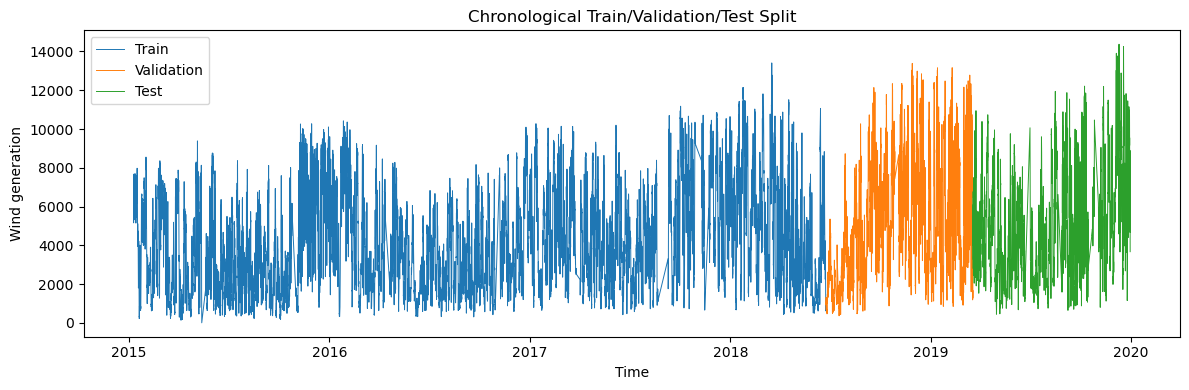

In [31]:
#Plot of choronological split

plt.figure(figsize=(12, 4))

plt.plot(train_df[TIMESTAMP_COL], train_df[TARGET_COL], label="Train", linewidth=0.7)
plt.plot(val_df[TIMESTAMP_COL], val_df[TARGET_COL], label="Validation", linewidth=0.7)
plt.plot(test_df[TIMESTAMP_COL], test_df[TARGET_COL], label="Test", linewidth=0.7)

plt.title("Chronological Train/Validation/Test Split")
plt.xlabel("Time")
plt.ylabel("Wind generation")
plt.legend()
plt.tight_layout()
plt.show()

## Baseline forecasting models

The baselines used are:

1. Mean baseline: predicts the mean wind generation from the training set.
2. Persistence baseline: predicts the previous hour's wind generation using `target_lag_1`.
3. Daily persistence baseline: predicts the value from 24 hours earlier using `target_lag_24`.
4. Weekly persistence baseline: predicts the value from 168 hours earlier using `target_lag_168`.

In [32]:


def regression_metrics(y_true, y_pred):
    """
    Compute common regression forecasting metrics.
    """
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2 = r2_score(y_true, y_pred)

    # Normalised RMSE by mean target value
    nrmse_mean = rmse / np.mean(y_true)

    # Normalised RMSE by target range
    nrmse_range = rmse / (np.max(y_true) - np.min(y_true))

    return {
        "MAE": mae,
        "RMSE": rmse,
        "nRMSE_mean": nrmse_mean,
        "nRMSE_range": nrmse_range,
        "R2": r2
    }

In [33]:
baseline_predictions = {}

# Mean baseline
train_mean = y_train.mean()
baseline_predictions["Mean baseline"] = np.full(shape=len(y_val), fill_value=train_mean)

baseline_predictions["Persistence lag_1"] = X_val["target_lag_1"].values
baseline_predictions["Daily persistence lag_24"] = X_val["target_lag_24"].values
baseline_predictions["Weekly persistence lag_168"] = X_val["target_lag_168"].values

In [34]:
baseline_results = []

for name, preds in baseline_predictions.items():
    metrics = regression_metrics(y_val, preds)
    metrics["Model"] = name
    baseline_results.append(metrics)

baseline_results_df = pd.DataFrame(baseline_results)

baseline_results_df = baseline_results_df[
    ["Model", "MAE", "RMSE", "nRMSE_mean", "nRMSE_range", "R2"]
].sort_values("RMSE")

display(baseline_results_df.round(4))

,Model,MAE,RMSE,nRMSE_mean,nRMSE_range,R2
1,Persistence lag_1,476.2529,942.0019,0.1702,0.0724,0.9101
2,Daily persistence lag_24,2336.4722,3056.4306,0.5523,0.2348,0.0531
0,Mean baseline,2754.5126,3404.5321,0.6152,0.2616,-0.1749
3,Weekly persistence lag_168,3275.5227,4080.8801,0.7374,0.3136,-0.6881


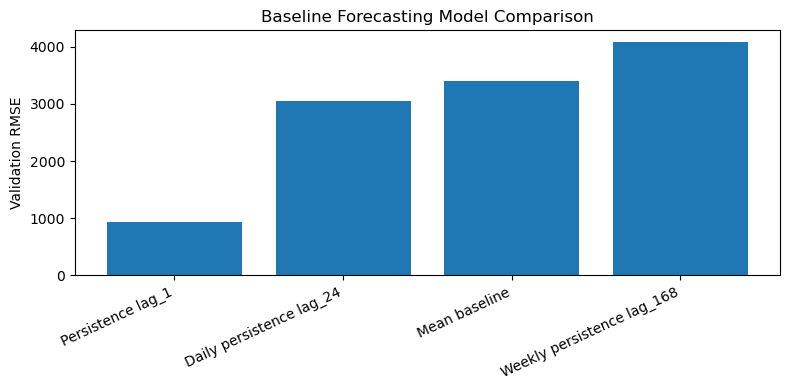

In [35]:
#Model Comparison Plot

plt.figure(figsize=(8, 4))
plt.bar(baseline_results_df["Model"], baseline_results_df["RMSE"])
plt.ylabel("Validation RMSE")
plt.title("Baseline Forecasting Model Comparison")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()

Best baseline by validation RMSE: Persistence lag_1


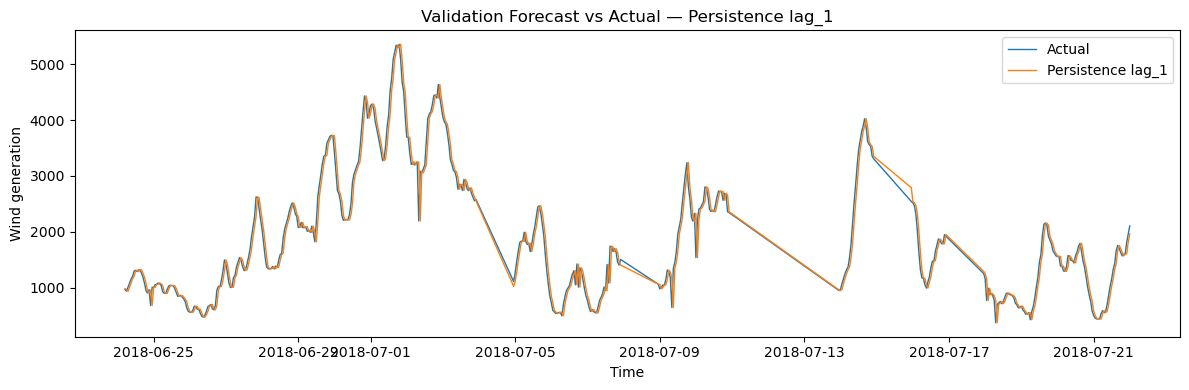

In [36]:
#Actual v/s Predicted of the best baseline model

best_baseline_name = baseline_results_df.iloc[0]["Model"]
best_baseline_pred = baseline_predictions[best_baseline_name]

print("Best baseline by validation RMSE:", best_baseline_name)

plot_n = min(500, len(y_val))

plt.figure(figsize=(12, 4))
plt.plot(val_df[TIMESTAMP_COL].iloc[:plot_n], y_val.iloc[:plot_n], label="Actual", linewidth=1)
plt.plot(val_df[TIMESTAMP_COL].iloc[:plot_n], best_baseline_pred[:plot_n], label=best_baseline_name, linewidth=1)
plt.title(f"Validation Forecast vs Actual — {best_baseline_name}")
plt.xlabel("Time")
plt.ylabel("Wind generation")
plt.legend()
plt.tight_layout()
plt.show()

In [37]:
best_baseline_rmse = baseline_results_df.iloc[0]["RMSE"]
best_baseline_mae = baseline_results_df.iloc[0]["MAE"]

print("Best baseline:", best_baseline_name)
print("Best baseline RMSE:", round(best_baseline_rmse, 3))
print("Best baseline MAE:", round(best_baseline_mae, 3))

Best baseline: Persistence lag_1
Best baseline RMSE: 942.002
Best baseline MAE: 476.253


## Machine learning model comparison

This section compares machine learning models against the best persistence baseline.

The validation set is used for model comparison.


In [38]:
# Define forecasting evaluation metrics

def regression_metrics(y_true, y_pred):
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2 = r2_score(y_true, y_pred)

    nrmse_mean = rmse / np.mean(y_true)
    nrmse_range = rmse / (np.max(y_true) - np.min(y_true))

    return {
        "MAE": mae,
        "RMSE": rmse,
        "nRMSE_mean": nrmse_mean,
        "nRMSE_range": nrmse_range,
        "R2": r2
    }


# Add RMSE improvement over the persistence baseline

def add_baseline_improvement(metrics, baseline_rmse):
    metrics["RMSE_improvement_%"] = (
        (baseline_rmse - metrics["RMSE"]) / baseline_rmse
    ) * 100
    return metrics

### Tabular machine learning models

The tabular models use the engineered feature set created earlier. Scaling and imputation are performed inside scikit-learn pipelines to avoid preprocessing leakage.

Tree-based models do not require scaling. Scale-sensitive models such as Ridge, ElasticNet, SVR, and MLP use StandardScaler inside the pipeline.

In [39]:

# Preprocessors
scaled_numeric_preprocessor = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

tree_numeric_preprocessor = Pipeline([
    ("imputer", SimpleImputer(strategy="median"))
])

In [40]:
#Parameters

tabular_models = {
    "Ridge Regression": {
        "model": Ridge(alpha=1.0, random_state=SEED),
        "preprocessor": scaled_numeric_preprocessor
    },

    "ElasticNet": {
        "model": ElasticNet(alpha=0.001, l1_ratio=0.2, max_iter=5000, random_state=SEED),
        "preprocessor": scaled_numeric_preprocessor
    },

    "Random Forest": {
        "model": RandomForestRegressor(
            n_estimators=200,
            max_depth=None,
            min_samples_leaf=2,
            random_state=SEED,
            n_jobs=-1
        ),
        "preprocessor": tree_numeric_preprocessor
    },

    "Extra Trees": {
        "model": ExtraTreesRegressor(
            n_estimators=200,
            max_depth=None,
            min_samples_leaf=2,
            random_state=SEED,
            n_jobs=-1
        ),
        "preprocessor": tree_numeric_preprocessor
    },

    "Gradient Boosting": {
        "model": GradientBoostingRegressor(
            n_estimators=200,
            learning_rate=0.05,
            max_depth=3,
            random_state=SEED
        ),
        "preprocessor": tree_numeric_preprocessor
    },

    "HistGradientBoosting": {
        "model": HistGradientBoostingRegressor(
            max_iter=300,
            learning_rate=0.05,
            max_leaf_nodes=31,
            l2_regularization=0.0,
            random_state=SEED
        ),
        "preprocessor": tree_numeric_preprocessor
    },

    "AdaBoost": {
        "model": AdaBoostRegressor(
            n_estimators=200,
            learning_rate=0.05,
            random_state=SEED
        ),
        "preprocessor": tree_numeric_preprocessor
    },

    "Linear SVR": {
        "model": LinearSVR(
            C=1.0,
            epsilon=0.1,
            max_iter=5000,
            random_state=SEED
        ),
        "preprocessor": scaled_numeric_preprocessor
    },

    "MLP Regressor": {
        "model": MLPRegressor(
            hidden_layer_sizes=(64, 32),
            activation="relu",
            alpha=0.0001,
            learning_rate_init=0.001,
            max_iter=300,
            early_stopping=True,
            random_state=SEED
        ),
        "preprocessor": scaled_numeric_preprocessor
    }
}

In [41]:
# Train and evaluate 

tabular_results = []
trained_tabular_models = {}

for name, config in tabular_models.items():
    pipe = Pipeline([
        ("preprocessor", config["preprocessor"]),
        ("model", config["model"])
    ])

    pipe.fit(X_train, y_train)

    y_val_pred = pipe.predict(X_val)

    metrics = regression_metrics(y_val, y_val_pred)
    metrics = add_baseline_improvement(metrics, best_baseline_rmse)
    metrics["Model"] = name
    metrics["Model type"] = "Tabular ML"

    tabular_results.append(metrics)
    trained_tabular_models[name] = pipe

tabular_results_df = pd.DataFrame(tabular_results)

tabular_results_df = tabular_results_df[
    ["Model", "Model type", "MAE", "RMSE", "nRMSE_mean", "nRMSE_range", "R2", "RMSE_improvement_%"]
].sort_values("RMSE")

display(tabular_results_df.round(4))

,Model,Model type,MAE,RMSE,nRMSE_mean,nRMSE_range,R2,RMSE_improvement_%
3,Extra Trees,Tabular ML,439.3262,818.3845,0.1479,0.0629,0.9321,13.1228
4,Gradient Boosting,Tabular ML,458.0047,833.5403,0.1506,0.0640,0.9296,11.5139
2,Random Forest,Tabular ML,460.7364,871.1986,0.1574,0.0669,0.9231,7.5163
7,Linear SVR,Tabular ML,483.2540,875.6452,0.1582,0.0673,0.9223,7.0442
8,MLP Regressor,Tabular ML,483.6840,878.2892,0.1587,0.0675,0.9218,6.7635
1,ElasticNet,Tabular ML,474.3715,881.6528,0.1593,0.0677,0.9212,6.4065
0,Ridge Regression,Tabular ML,472.4773,884.0025,0.1597,0.0679,0.9208,6.1570
5,HistGradientBoosting,Tabular ML,521.8943,905.6707,0.1637,0.0696,0.9169,3.8568
6,AdaBoost,Tabular ML,744.6133,1072.7229,0.1938,0.0824,0.8834,-13.8769


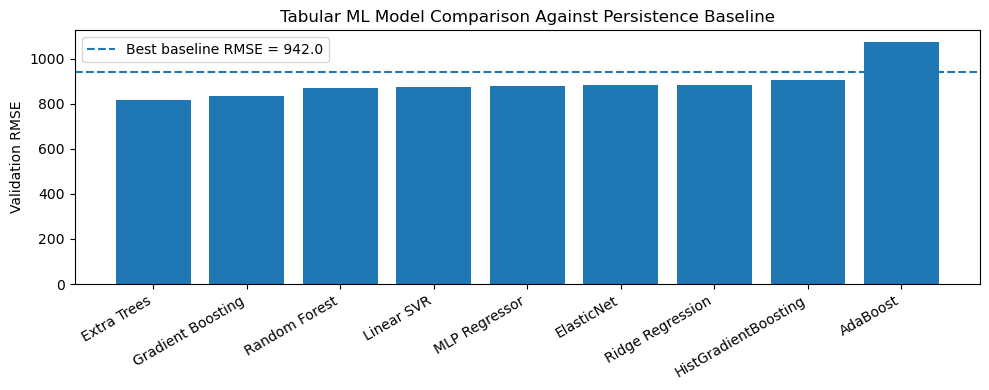

In [42]:
#Model Comparison plot
plt.figure(figsize=(10, 4))
plt.bar(tabular_results_df["Model"], tabular_results_df["RMSE"])
plt.axhline(best_baseline_rmse, linestyle="--", label=f"Best baseline RMSE = {best_baseline_rmse:.1f}")
plt.ylabel("Validation RMSE")
plt.title("Tabular ML Model Comparison Against Persistence Baseline")
plt.xticks(rotation=30, ha="right")
plt.legend()
plt.tight_layout()
plt.show()

In [43]:
#Final Models(Baseline + Adanvanced) comparsion table

baseline_results_df["RMSE_improvement_%"] = (
    (best_baseline_rmse - baseline_results_df["RMSE"]) / best_baseline_rmse
) * 100

baseline_results_df["Model type"] = "Baseline"

combined_parts = [
    baseline_results_df,
    tabular_results_df
]


all_validation_results_df = pd.concat(combined_parts, ignore_index=True)

all_validation_results_df = all_validation_results_df[
    ["Model", "Model type", "MAE", "RMSE", "nRMSE_mean", "nRMSE_range", "R2", "RMSE_improvement_%"]
].sort_values("RMSE")

display(all_validation_results_df.round(4))

,Model,Model type,MAE,RMSE,nRMSE_mean,nRMSE_range,R2,RMSE_improvement_%
4,Extra Trees,Tabular ML,439.3262,818.3845,0.1479,0.0629,0.9321,13.1228
5,Gradient Boosting,Tabular ML,458.0047,833.5403,0.1506,0.0640,0.9296,11.5139
6,Random Forest,Tabular ML,460.7364,871.1986,0.1574,0.0669,0.9231,7.5163
7,Linear SVR,Tabular ML,483.2540,875.6452,0.1582,0.0673,0.9223,7.0442
8,MLP Regressor,Tabular ML,483.6840,878.2892,0.1587,0.0675,0.9218,6.7635
9,ElasticNet,Tabular ML,474.3715,881.6528,0.1593,0.0677,0.9212,6.4065
10,Ridge Regression,Tabular ML,472.4773,884.0025,0.1597,0.0679,0.9208,6.1570
11,HistGradientBoosting,Tabular ML,521.8943,905.6707,0.1637,0.0696,0.9169,3.8568
0,Persistence lag_1,Baseline,476.2529,942.0019,0.1702,0.0724,0.9101,0.0000
12,AdaBoost,Tabular ML,744.6133,1072.7229,0.1938,0.0824,0.8834,-13.8769


## Hyperparameter tuning

The strongest models from the validation comparison were Extra Trees, Gradient Boosting, and Random Forest. These models are tuned using `GridSearchCV` with `TimeSeriesSplit` on the training set only.


RMSE is used as the main optimisation metric.

In [44]:
# Define time-series CV and tuning metrics

tscv = TimeSeriesSplit(n_splits=3)

scoring = {
    "neg_rmse": "neg_root_mean_squared_error",
    "neg_mae": "neg_mean_absolute_error",
    "r2": "r2"
}


In [45]:
# Define tuned tree-based model pipelines and parameter grids

tree_numeric_preprocessor = Pipeline([
    ("imputer", SimpleImputer(strategy="median"))
])

tuning_models = {
    "Extra Trees": {
        "pipeline": Pipeline([
            ("preprocessor", tree_numeric_preprocessor),
            ("model", ExtraTreesRegressor(
                random_state=SEED,
                n_jobs=-1
            ))
        ]),
        "param_grid": {
            "model__n_estimators": [200, 300],
            "model__max_depth": [None, 30],
            "model__min_samples_leaf": [1, 2],
            "model__max_features": [0.7, 1.0]
        }
    },

    "Gradient Boosting": {
        "pipeline": Pipeline([
            ("preprocessor", tree_numeric_preprocessor),
            ("model", GradientBoostingRegressor(
                random_state=SEED
            ))
        ]),
        "param_grid": {
            "model__n_estimators": [150, 250],
            "model__learning_rate": [0.03, 0.05],
            "model__max_depth": [2, 3],
            "model__min_samples_leaf": [1, 3],
            "model__subsample": [0.8, 1.0]
        }
    },

    "Random Forest": {
        "pipeline": Pipeline([
            ("preprocessor", tree_numeric_preprocessor),
            ("model", RandomForestRegressor(
                random_state=SEED,
                n_jobs=-1
            ))
        ]),
        "param_grid": {
            "model__n_estimators": [200, 300],
            "model__max_depth": [None, 30],
            "model__min_samples_leaf": [1, 2],
            "model__max_features": [0.7, 1.0]
        }
    }
}

In [46]:
tuned_results = []
tuned_models = {}
tuned_cv_results = {}

for name, config in tuning_models.items():
    print(f"\nTuning: {name}")

    grid_search = GridSearchCV(
        estimator=config["pipeline"],
        param_grid=config["param_grid"],
        scoring=scoring,
        refit="neg_rmse",
        cv=tscv,
        n_jobs=-1,
        return_train_score=False,
        verbose=1
    )

    grid_search.fit(X_train, y_train)

    tuned_models[name] = grid_search.best_estimator_
    tuned_cv_results[name] = grid_search.cv_results_

    best_cv_rmse = -grid_search.best_score_

    print("Best CV RMSE:", round(best_cv_rmse, 3))
    print("Best parameters:", grid_search.best_params_)

    # Validation evaluation
    y_val_pred = grid_search.best_estimator_.predict(X_val)

    metrics = regression_metrics(y_val, y_val_pred)
    metrics = add_baseline_improvement(metrics, best_baseline_rmse)

    metrics["Model"] = name
    metrics["Model type"] = "Tuned ML"
    metrics["Best CV RMSE"] = best_cv_rmse
    metrics["Best parameters"] = grid_search.best_params_

    tuned_results.append(metrics)


Tuning: Extra Trees
Fitting 3 folds for each of 16 candidates, totalling 48 fits


Best CV RMSE: 501.719
Best parameters: {'model__max_depth': None, 'model__max_features': 1.0, 'model__min_samples_leaf': 2, 'model__n_estimators': 300}

Tuning: Gradient Boosting
Fitting 3 folds for each of 32 candidates, totalling 96 fits
Best CV RMSE: 521.989
Best parameters: {'model__learning_rate': 0.03, 'model__max_depth': 3, 'model__min_samples_leaf': 3, 'model__n_estimators': 250, 'model__subsample': 1.0}

Tuning: Random Forest
Fitting 3 folds for each of 16 candidates, totalling 48 fits
Best CV RMSE: 514.176
Best parameters: {'model__max_depth': 30, 'model__max_features': 0.7, 'model__min_samples_leaf': 2, 'model__n_estimators': 200}


In [47]:
tuned_results_df = pd.DataFrame(tuned_results)

tuned_results_df = tuned_results_df[
    [
        "Model",
        "Model type",
        "Best CV RMSE",
        "MAE",
        "RMSE",
        "nRMSE_mean",
        "nRMSE_range",
        "R2",
        "RMSE_improvement_%",
        "Best parameters"
    ]
].sort_values("RMSE")

display(tuned_results_df.round(4))

,Model,Model type,Best CV RMSE,MAE,RMSE,nRMSE_mean,nRMSE_range,R2,RMSE_improvement_%,Best parameters
0,Extra Trees,Tuned ML,501.7188,437.7011,817.3727,0.1477,0.0628,0.9323,13.2302,"{'model__max_depth': None, 'model__max_feature..."
1,Gradient Boosting,Tuned ML,521.9885,462.7515,839.6932,0.1517,0.0645,0.9285,10.8608,"{'model__learning_rate': 0.03, 'model__max_dep..."
2,Random Forest,Tuned ML,514.1759,459.7676,845.9792,0.1529,0.0650,0.9275,10.1935,"{'model__max_depth': 30, 'model__max_features'..."


In [48]:
top_untuned_df = all_validation_results_df[
    all_validation_results_df["Model"].isin(["Extra Trees", "Gradient Boosting", "Random Forest"])
].copy()

comparison_tuned_untuned_df = pd.concat(
    [
        top_untuned_df.assign(Stage="Untuned"),
        tuned_results_df.assign(Stage="Tuned")
    ],
    ignore_index=True
)

comparison_tuned_untuned_df = comparison_tuned_untuned_df[
    ["Stage", "Model", "Model type", "MAE", "RMSE", "R2", "RMSE_improvement_%"]
].sort_values("RMSE")

display(comparison_tuned_untuned_df.round(4))

,Stage,Model,Model type,MAE,RMSE,R2,RMSE_improvement_%
3,Tuned,Extra Trees,Tuned ML,437.7011,817.3727,0.9323,13.2302
0,Untuned,Extra Trees,Tabular ML,439.3262,818.3845,0.9321,13.1228
1,Untuned,Gradient Boosting,Tabular ML,458.0047,833.5403,0.9296,11.5139
4,Tuned,Gradient Boosting,Tuned ML,462.7515,839.6932,0.9285,10.8608
5,Tuned,Random Forest,Tuned ML,459.7676,845.9792,0.9275,10.1935
2,Untuned,Random Forest,Tabular ML,460.7364,871.1986,0.9231,7.5163


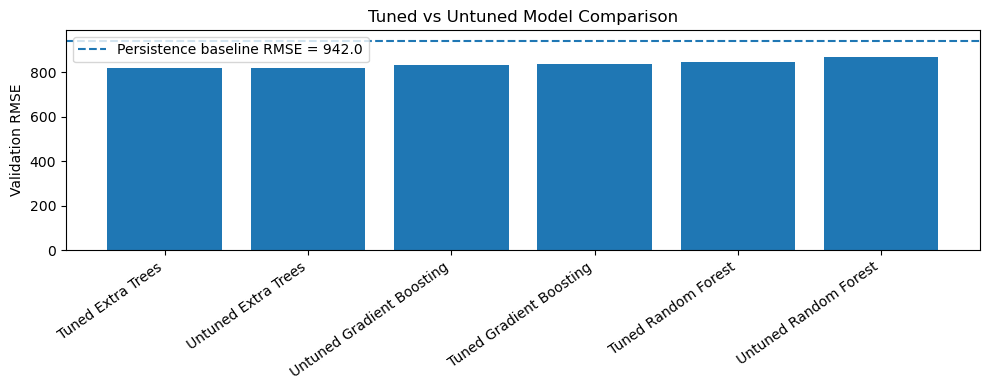

In [49]:
plt.figure(figsize=(10, 4))

plt.bar(
    comparison_tuned_untuned_df["Stage"] + " " + comparison_tuned_untuned_df["Model"],
    comparison_tuned_untuned_df["RMSE"]
)

plt.axhline(
    best_baseline_rmse,
    linestyle="--",
    label=f"Persistence baseline RMSE = {best_baseline_rmse:.1f}"
)

plt.ylabel("Validation RMSE")
plt.title("Tuned vs Untuned Model Comparison")
plt.xticks(rotation=35, ha="right")
plt.legend()
plt.tight_layout()
plt.show()

In [50]:
candidate_pool_df = pd.concat(
    [
        all_validation_results_df.assign(Stage="Section 8"),
        tuned_results_df.assign(Stage="Tuned")
    ],
    ignore_index=True
)

candidate_pool_df = candidate_pool_df[
    ["Stage", "Model", "Model type", "MAE", "RMSE", "nRMSE_mean", "nRMSE_range", "R2", "RMSE_improvement_%"]
].sort_values("RMSE")

display(candidate_pool_df.round(4))

,Stage,Model,Model type,MAE,RMSE,nRMSE_mean,nRMSE_range,R2,RMSE_improvement_%
13,Tuned,Extra Trees,Tuned ML,437.7011,817.3727,0.1477,0.0628,0.9323,13.2302
0,Section 8,Extra Trees,Tabular ML,439.3262,818.3845,0.1479,0.0629,0.9321,13.1228
1,Section 8,Gradient Boosting,Tabular ML,458.0047,833.5403,0.1506,0.0640,0.9296,11.5139
14,Tuned,Gradient Boosting,Tuned ML,462.7515,839.6932,0.1517,0.0645,0.9285,10.8608
15,Tuned,Random Forest,Tuned ML,459.7676,845.9792,0.1529,0.0650,0.9275,10.1935
2,Section 8,Random Forest,Tabular ML,460.7364,871.1986,0.1574,0.0669,0.9231,7.5163
3,Section 8,Linear SVR,Tabular ML,483.2540,875.6452,0.1582,0.0673,0.9223,7.0442
4,Section 8,MLP Regressor,Tabular ML,483.6840,878.2892,0.1587,0.0675,0.9218,6.7635
5,Section 8,ElasticNet,Tabular ML,474.3715,881.6528,0.1593,0.0677,0.9212,6.4065
6,Section 8,Ridge Regression,Tabular ML,472.4773,884.0025,0.1597,0.0679,0.9208,6.1570


In [51]:
best_candidate_row = candidate_pool_df.iloc[0]

best_model_name = best_candidate_row["Model"]
best_model_stage = best_candidate_row["Stage"]
best_model_type = best_candidate_row["Model type"]

print("Selected final candidate model:", best_model_name)
print("Stage:", best_model_stage)
print("Model type:", best_model_type)
print("Validation RMSE:", round(best_candidate_row["RMSE"], 3))
print("Validation MAE:", round(best_candidate_row["MAE"], 3))
print("Validation R2:", round(best_candidate_row["R2"], 4))
print("Improvement over persistence:", round(best_candidate_row["RMSE_improvement_%"], 2), "%")

Selected final candidate model: Extra Trees
Stage: Tuned
Model type: Tuned ML
Validation RMSE: 817.373
Validation MAE: 437.701
Validation R2: 0.9323
Improvement over persistence: 13.23 %


In [52]:
if best_model_stage == "Tuned":
    best_model = tuned_models[best_model_name]
elif best_model_type == "Tabular ML":
    best_model = trained_tabular_models[best_model_name]
elif best_model_type == "Baseline":
    best_model = None
else:
    best_model = None

print("Best model object stored:", best_model is not None)

Best model object stored: True


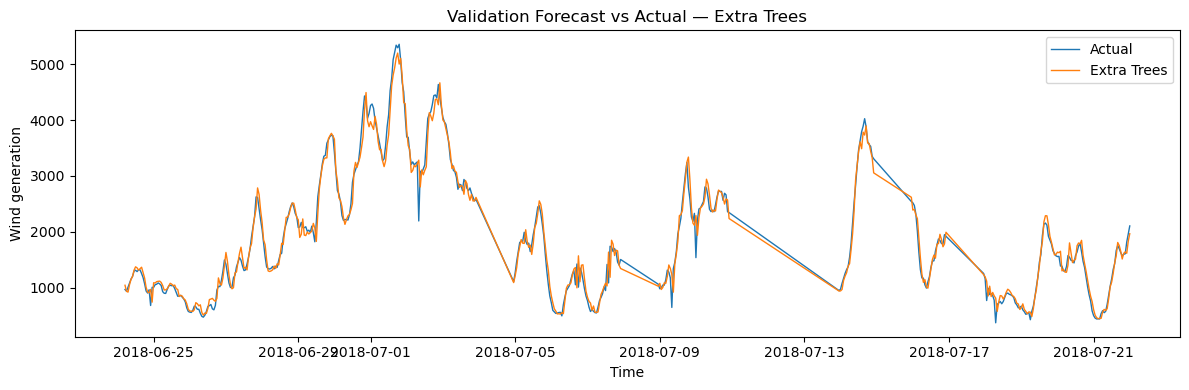

In [53]:
if best_model is not None:
    y_val_best_pred = best_model.predict(X_val)
else:
    y_val_best_pred = baseline_predictions[best_model_name]

plot_n = min(500, len(y_val))

plt.figure(figsize=(12, 4))
plt.plot(val_df[TIMESTAMP_COL].iloc[:plot_n], y_val.iloc[:plot_n], label="Actual", linewidth=1)
plt.plot(val_df[TIMESTAMP_COL].iloc[:plot_n], y_val_best_pred[:plot_n], label=best_model_name, linewidth=1)

plt.title(f"Validation Forecast vs Actual — {best_model_name}")
plt.xlabel("Time")
plt.ylabel("Wind generation")
plt.legend()
plt.tight_layout()
plt.show()

##  Final test set evaluation

The final candidate model selected from validation results is the tuned Extra Trees model.

The model choice and hyperparameters are now fixed. The final test set is used once to estimate generalisation performance on the latest unseen time period.


In [54]:
# Combine train and validation data after model selection
X_trainval = pd.concat([X_train, X_val], axis=0)
y_trainval = pd.concat([y_train, y_val], axis=0)

print("X_trainval:", X_trainval.shape)
print("y_trainval:", y_trainval.shape)
print("X_test:", X_test.shape)
print("y_test:", y_test.shape)

# Clone the selected model so the validation-fitted model is preserved
final_model = clone(best_model)

# Fit final fixed model on train + validation only
final_model.fit(X_trainval, y_trainval)

print("Final model refitted on train + validation data.")

X_trainval: (34419, 36)
y_trainval: (34419,)
X_test: (6075, 36)
y_test: (6075,)
Final model refitted on train + validation data.


In [55]:
test_baseline_predictions = {
    "Persistence lag_1": X_test["target_lag_1"].values,
    "Daily persistence lag_24": X_test["target_lag_24"].values,
    "Weekly persistence lag_168": X_test["target_lag_168"].values
}

test_baseline_results = []

for name, preds in test_baseline_predictions.items():
    metrics = regression_metrics(y_test, preds)
    metrics["Model"] = name
    metrics["Model type"] = "Test baseline"
    test_baseline_results.append(metrics)

test_baseline_results_df = pd.DataFrame(test_baseline_results)

test_baseline_results_df = test_baseline_results_df[
    ["Model", "Model type", "MAE", "RMSE", "nRMSE_mean", "nRMSE_range", "R2"]
].sort_values("RMSE")

display(test_baseline_results_df.round(4))

best_test_baseline_rmse = test_baseline_results_df.iloc[0]["RMSE"]
best_test_baseline_name = test_baseline_results_df.iloc[0]["Model"]

print("Best test baseline:", best_test_baseline_name)
print("Best test baseline RMSE:", round(best_test_baseline_rmse, 3))

,Model,Model type,MAE,RMSE,nRMSE_mean,nRMSE_range,R2
0,Persistence lag_1,Test baseline,429.3289,878.0516,0.1669,0.0631,0.9038
1,Daily persistence lag_24,Test baseline,2305.7361,2983.5292,0.5672,0.2143,-0.1105
2,Weekly persistence lag_168,Test baseline,2895.6298,3631.4627,0.6904,0.2609,-0.6452


Best test baseline: Persistence lag_1
Best test baseline RMSE: 878.052


In [56]:
y_test_pred = final_model.predict(X_test)

final_test_metrics = regression_metrics(y_test, y_test_pred)

final_test_metrics["RMSE_improvement_vs_test_baseline_%"] = (
    (best_test_baseline_rmse - final_test_metrics["RMSE"]) / best_test_baseline_rmse
) * 100

final_test_results_df = pd.DataFrame(
    final_test_metrics.items(),
    columns=["Metric", "Final test score"]
)

display(final_test_results_df.round(4))

,Metric,Final test score
0,MAE,389.4002
1,RMSE,747.2488
2,nRMSE_mean,0.1421
3,nRMSE_range,0.0537
4,R2,0.9303
5,RMSE_improvement_vs_test_baseline_%,14.8969


In [57]:
final_model_row = {
    "Model": "Tuned Extra Trees",
    "Model type": "Final model",
    "MAE": final_test_metrics["MAE"],
    "RMSE": final_test_metrics["RMSE"],
    "nRMSE_mean": final_test_metrics["nRMSE_mean"],
    "nRMSE_range": final_test_metrics["nRMSE_range"],
    "R2": final_test_metrics["R2"],
    "RMSE_improvement_%": final_test_metrics["RMSE_improvement_vs_test_baseline_%"]
}

test_comparison_df = pd.concat(
    [
        test_baseline_results_df.assign(RMSE_improvement_=np.nan),
        pd.DataFrame([final_model_row])
    ],
    ignore_index=True
)

test_comparison_df = test_comparison_df[
    ["Model", "Model type", "MAE", "RMSE", "nRMSE_mean", "nRMSE_range", "R2", "RMSE_improvement_%"]
].sort_values("RMSE")

display(test_comparison_df.round(4))

,Model,Model type,MAE,RMSE,nRMSE_mean,nRMSE_range,R2,RMSE_improvement_%
3,Tuned Extra Trees,Final model,389.4002,747.2488,0.1421,0.0537,0.9303,14.8969
0,Persistence lag_1,Test baseline,429.3289,878.0516,0.1669,0.0631,0.9038,NaN
1,Daily persistence lag_24,Test baseline,2305.7361,2983.5292,0.5672,0.2143,-0.1105,NaN
2,Weekly persistence lag_168,Test baseline,2895.6298,3631.4627,0.6904,0.2609,-0.6452,NaN


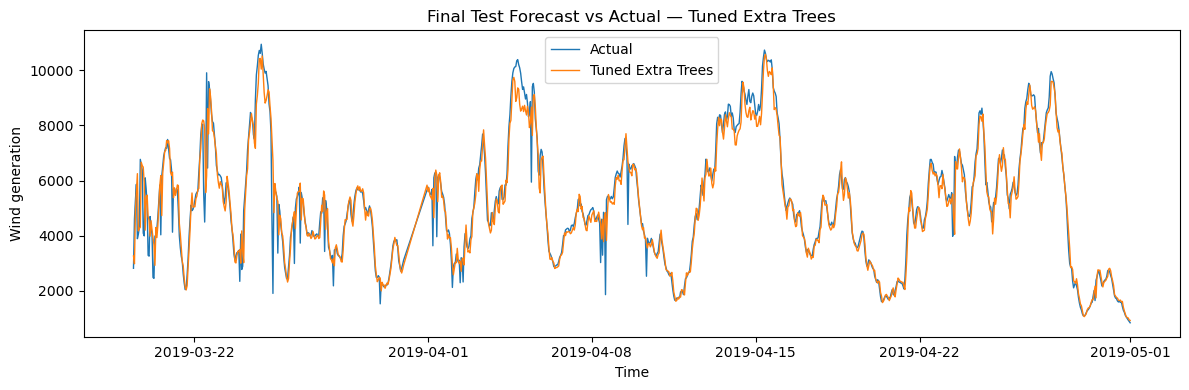

In [58]:
plot_n = min(1000, len(y_test))

plt.figure(figsize=(12, 4))
plt.plot(
    test_df[TIMESTAMP_COL].iloc[:plot_n],
    y_test.iloc[:plot_n],
    label="Actual",
    linewidth=1
)
plt.plot(
    test_df[TIMESTAMP_COL].iloc[:plot_n],
    y_test_pred[:plot_n],
    label="Tuned Extra Trees",
    linewidth=1
)

plt.title("Final Test Forecast vs Actual — Tuned Extra Trees")
plt.xlabel("Time")
plt.ylabel("Wind generation")
plt.legend()
plt.tight_layout()
plt.savefig("fig_final_test_forecast_vs_actual.png", dpi=150, bbox_inches="tight")
plt.show()

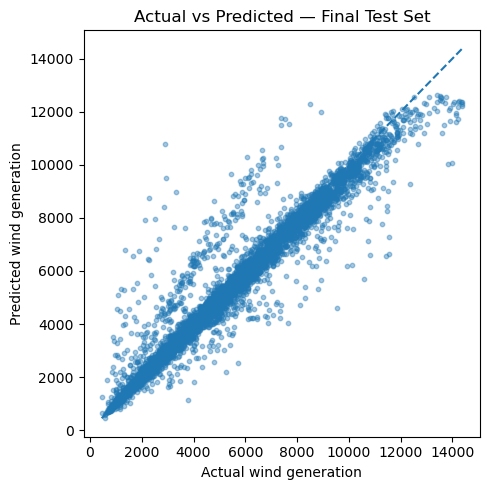

In [59]:
plt.figure(figsize=(5, 5))
plt.scatter(y_test, y_test_pred, alpha=0.4, s=10)

min_val = min(y_test.min(), y_test_pred.min())
max_val = max(y_test.max(), y_test_pred.max())

plt.plot([min_val, max_val], [min_val, max_val], linestyle="--")
plt.xlabel("Actual wind generation")
plt.ylabel("Predicted wind generation")
plt.title("Actual vs Predicted — Final Test Set")
plt.tight_layout()
plt.savefig("fig_final_actual_vs_predicted.png", dpi=150, bbox_inches="tight")
plt.show()

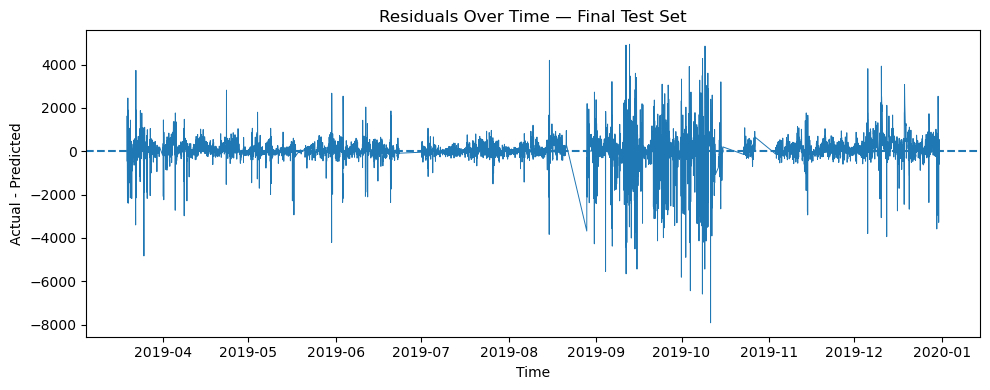

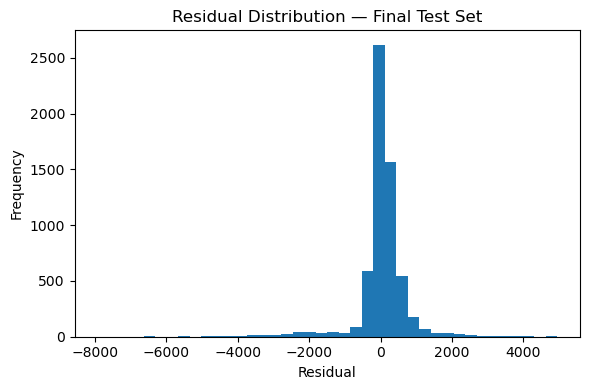

In [60]:
test_residuals = y_test.values - y_test_pred

plt.figure(figsize=(10, 4))
plt.plot(test_df[TIMESTAMP_COL], test_residuals, linewidth=0.7)
plt.axhline(0, linestyle="--")
plt.title("Residuals Over Time — Final Test Set")
plt.xlabel("Time")
plt.ylabel("Actual - Predicted")
plt.tight_layout()
plt.savefig("fig_final_residuals_over_time.png", dpi=150, bbox_inches="tight")
plt.show()

plt.figure(figsize=(6, 4))
plt.hist(test_residuals, bins=40)
plt.title("Residual Distribution — Final Test Set")
plt.xlabel("Residual")
plt.ylabel("Frequency")
plt.tight_layout()
plt.savefig("fig_final_residual_distribution.png", dpi=150, bbox_inches="tight")
plt.show()

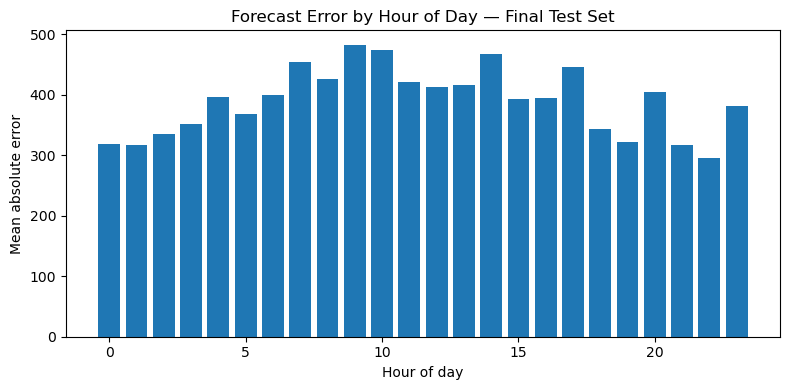

In [61]:
test_error_df = test_df[[TIMESTAMP_COL, TARGET_COL]].copy()
test_error_df["prediction"] = y_test_pred
test_error_df["absolute_error"] = np.abs(test_error_df[TARGET_COL] - test_error_df["prediction"])
test_error_df["hour"] = test_error_df[TIMESTAMP_COL].dt.hour
test_error_df["month"] = test_error_df[TIMESTAMP_COL].dt.month

hourly_error = test_error_df.groupby("hour")["absolute_error"].mean()

plt.figure(figsize=(8, 4))
plt.bar(hourly_error.index, hourly_error.values)
plt.xlabel("Hour of day")
plt.ylabel("Mean absolute error")
plt.title("Forecast Error by Hour of Day — Final Test Set")
plt.tight_layout()
plt.savefig("fig_error_by_hour.png", dpi=150, bbox_inches="tight")
plt.show()

## Statistical comparison using Wilcoxon signed-rank test

The top two tuned models were compared using a paired Wilcoxon signed-rank test on validation absolute errors.

This test compares whether the difference in paired errors between two models is systematically different from zero. 



In [62]:
from scipy.stats import wilcoxon

# Top two tuned models
model_a_name = "Extra Trees"
model_b_name = "Gradient Boosting"

model_a = tuned_models[model_a_name]
model_b = tuned_models[model_b_name]

# Validation predictions
y_val_pred_a = model_a.predict(X_val)
y_val_pred_b = model_b.predict(X_val)

# Absolute errors
abs_error_a = np.abs(y_val.values - y_val_pred_a)
abs_error_b = np.abs(y_val.values - y_val_pred_b)

# Wilcoxon signed-rank test on paired absolute errors
statistic, p_value = wilcoxon(abs_error_a, abs_error_b)

print(f"Wilcoxon comparison: {model_a_name} vs {model_b_name}")
print("Statistic:", statistic)
print("p-value:", p_value)

print("\nMean absolute error:")
print(model_a_name, ":", abs_error_a.mean())
print(model_b_name, ":", abs_error_b.mean())

print("\nMedian absolute error:")
print(model_a_name, ":", np.median(abs_error_a))
print(model_b_name, ":", np.median(abs_error_b))

Wilcoxon comparison: Extra Trees vs Gradient Boosting
Statistic: 7789473.0
p-value: 8.39185591228637e-26

Mean absolute error:
Extra Trees : 437.70114939816335
Gradient Boosting : 462.75154847520264

Median absolute error:
Extra Trees : 214.5774999999992
Gradient Boosting : 238.9435468537664


In [63]:
wilcoxon_df = val_df[[TIMESTAMP_COL]].copy()
wilcoxon_df["abs_error_extra_trees"] = abs_error_a
wilcoxon_df["abs_error_gradient_boosting"] = abs_error_b
wilcoxon_df["date"] = wilcoxon_df[TIMESTAMP_COL].dt.date

daily_errors = wilcoxon_df.groupby("date")[
    ["abs_error_extra_trees", "abs_error_gradient_boosting"]
].mean()

daily_statistic, daily_p_value = wilcoxon(
    daily_errors["abs_error_extra_trees"],
    daily_errors["abs_error_gradient_boosting"]
)

print("Daily aggregated Wilcoxon test")
print("Statistic:", daily_statistic)
print("p-value:", daily_p_value)

display(daily_errors.describe().round(3))

Daily aggregated Wilcoxon test
Statistic: 8164.0
p-value: 4.12994900775493e-13


,abs_error_extra_trees,abs_error_gradient_boosting
count,260.000,260.000
mean,427.931,453.061
std,412.457,408.857
min,8.260,0.093
25%,178.030,206.295
50%,299.373,331.477
75%,498.007,554.592
max,2422.788,2578.566


## Interpretability and feature importance

The final tuned Extra Trees model is interpreted using feature importance and permutation importance. The aim is to identify which engineered predictors were most associated with accurate wind generation forecasts.

In [64]:
# Extract the fitted Extra Trees model from the final pipeline
final_estimator = final_model.named_steps["model"]

feature_importance_df = pd.DataFrame({
    "Feature": final_feature_cols,
    "Importance": final_estimator.feature_importances_
}).sort_values("Importance", ascending=False)

display(feature_importance_df.head(20).round(4))

,Feature,Importance
19,target_lag_1,0.2714
27,target_rolling_mean_3,0.2334
20,target_lag_2,0.1910
28,target_rolling_mean_6,0.1464
21,target_lag_3,0.0994
22,target_lag_6,0.0283
29,target_rolling_mean_24,0.0041
23,target_lag_12,0.0035
24,target_lag_24,0.0015
13,hour_sin,0.0012


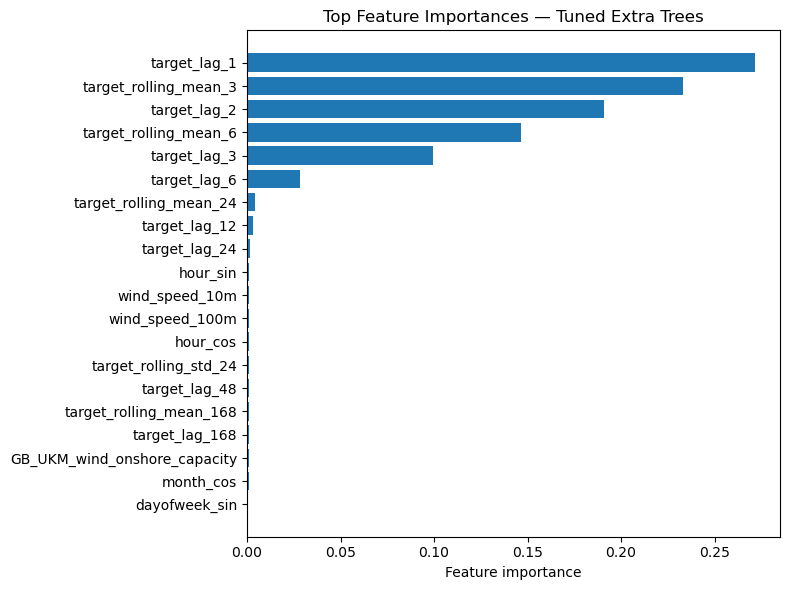

In [65]:
top_features = feature_importance_df.head(20).sort_values("Importance")

plt.figure(figsize=(8, 6))
plt.barh(top_features["Feature"], top_features["Importance"])
plt.xlabel("Feature importance")
plt.title("Top Feature Importances — Tuned Extra Trees")
plt.tight_layout()
plt.savefig("fig_feature_importance_extra_trees.png", dpi=150, bbox_inches="tight")
plt.show()

In [66]:
# Compute permutation importance on the validation set.
perm_result = permutation_importance(
    final_model,
    X_val,
    y_val,
    scoring="neg_root_mean_squared_error",
    n_repeats=10,
    random_state=SEED,
    n_jobs=-1
)

perm_importance_df = pd.DataFrame({
    "Feature": final_feature_cols,
    "Importance mean": perm_result.importances_mean,
    "Importance std": perm_result.importances_std
}).sort_values("Importance mean", ascending=False)

display(perm_importance_df.head(20).round(4))

,Feature,Importance mean,Importance std
19,target_lag_1,1596.9283,9.1546
27,target_rolling_mean_3,1248.4238,8.1544
20,target_lag_2,597.8890,4.8484
28,target_rolling_mean_6,401.2632,5.4826
21,target_lag_3,309.2134,3.7865
22,target_lag_6,139.1458,4.4809
14,hour_cos,66.1006,3.0264
13,hour_sin,58.5873,2.6217
30,target_rolling_std_24,42.4348,0.9591
31,target_rolling_mean_168,40.9432,0.9355


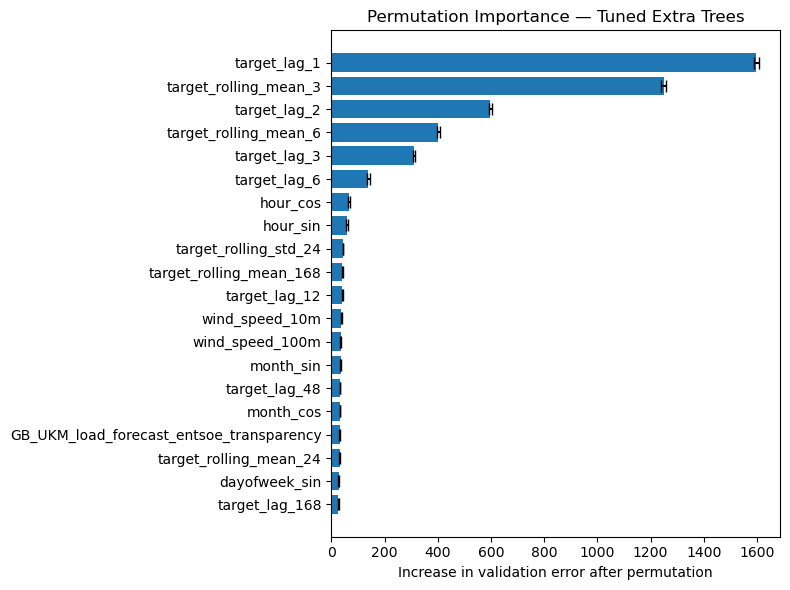

In [67]:
# Plot permutation importance.
top_perm = perm_importance_df.head(20).sort_values("Importance mean")

plt.figure(figsize=(8, 6))
plt.barh(
    top_perm["Feature"],
    top_perm["Importance mean"],
    xerr=top_perm["Importance std"],
    capsize=4
)
plt.xlabel("Increase in validation error after permutation")
plt.title("Permutation Importance — Tuned Extra Trees")
plt.tight_layout()
plt.savefig("fig_permutation_importance_extra_trees.png", dpi=150, bbox_inches="tight")
plt.show()

## Error analysis

This section analyses the final tuned Extra Trees model's errors on the held-out test set. The aim is to identify whether large forecast errors occur during particular times, generation levels, or rapid changes in wind generation.

The model is not changed after this analysis. The purpose is only to understand model behaviour and limitations.

In [68]:
test_error_df = test_df[[TIMESTAMP_COL, TARGET_COL]].copy()

test_error_df["prediction"] = y_test_pred
test_error_df["residual"] = test_error_df[TARGET_COL] - test_error_df["prediction"]
test_error_df["absolute_error"] = np.abs(test_error_df["residual"])
test_error_df["squared_error"] = test_error_df["residual"] ** 2

test_error_df["hour"] = test_error_df[TIMESTAMP_COL].dt.hour
test_error_df["dayofweek"] = test_error_df[TIMESTAMP_COL].dt.dayofweek
test_error_df["month"] = test_error_df[TIMESTAMP_COL].dt.month

display(test_error_df.head())

print("Absolute error summary:")
display(test_error_df["absolute_error"].describe().round(3))

print("Residual summary:")
display(test_error_df["residual"].describe().round(3))

,utc_timestamp,GB_UKM_wind_generation_actual,prediction,residual,absolute_error,squared_error,hour,dayofweek,month
34419,2019-03-19 10:00:00,2823.0,3268.946389,-445.946389,445.946389,1.988682e+05,10,1,3
34420,2019-03-19 11:00:00,4617.0,2986.763333,1630.236667,1630.236667,2.657672e+06,11,1,3
34421,2019-03-19 12:00:00,5307.0,4925.123889,381.876111,381.876111,1.458294e+05,12,1,3
34422,2019-03-19 13:00:00,5869.0,5597.111111,271.888889,271.888889,7.392357e+04,13,1,3
34423,2019-03-19 14:00:00,3896.0,6253.545000,-2357.545000,2357.545000,5.558018e+06,14,1,3


Absolute error summary:


count    6075.000
mean      389.400
std       637.821
min         0.058
25%        78.682
50%       185.098
75%       398.469
max      7915.392
Name: absolute_error, dtype: float64

Residual summary:


count    6075.000
mean       42.625
std       746.094
min     -7915.392
25%      -108.467
50%        51.697
75%       271.588
max      4940.206
Name: residual, dtype: float64

In [69]:
largest_errors = test_error_df.sort_values(
    "absolute_error",
    ascending=False
).head(15)

display(
    largest_errors[
        [TIMESTAMP_COL, TARGET_COL, "prediction", "residual", "absolute_error"]
    ].round(3)
)

,utc_timestamp,GB_UKM_wind_generation_actual,prediction,residual,absolute_error
38926,2019-10-11 06:00:00,2886.0,10801.392,-7915.392,7915.392
38857,2019-10-08 09:00:00,2927.0,9515.287,-6588.287,6588.287
38755,2019-10-04 03:00:00,2295.0,8730.857,-6435.857,6435.857
38679,2019-09-30 23:00:00,2122.0,7931.969,-5809.969,5809.969
38211,2019-09-11 11:00:00,3317.0,8972.910,-5655.910,5655.910
38037,2019-09-04 05:00:00,2852.0,8400.158,-5548.158,5548.158
38303,2019-09-15 07:00:00,1360.0,6795.563,-5435.563,5435.563
38877,2019-10-09 05:00:00,2524.0,7959.396,-5435.396,5435.396
38240,2019-09-12 16:00:00,9547.0,4606.794,4940.206,4940.206
38210,2019-09-11 10:00:00,11544.0,6645.853,4898.147,4898.147
